# От одного колебания к $\delta_{\mathrm{eq}}$

Частица в стационарной сепаратрисе колеблется вокруг импульса, который сам чуть сдвинут относительно синхронного. Этот сдвиг

$$
\delta_{\mathrm{eq}}
=
-\frac{\eta_1\,\delta_m^2/2+\Lambda}{\eta_0},
\qquad
\Lambda
=
-\frac{2\pi}{C}\bigl(J_x\xi_x+J_y\xi_y\bigr)
$$

и есть предмет этой тетради.

Порядок как в заметке `note/main.tex`: сначала одна частица и один график, потом усреднение, бетатрон, тор, четыре модели. Секступолей в решётке нет, спин не вводился — оба вопроса названы в конце, а не спрятаны.

Длинный прогон на $1.2\cdot10^4$ оборотов уже сделан скриптом `scripts/run_v08.jl` и лежит в `note/figs` и `note/gen`. Здесь живые короткие ряды, чтобы явление было видно, и ссылки на уже посчитанные цифры согласия.


## Как открыть тетрадь

В Cursor в правом верхнем углу тетради выберите ядро **Julia EquilibriumEnergy 1.13**, не Python. После этого ячейки запускаются кнопкой Run или Shift+Enter.

Из REPL, если удобнее Jupyter в браузере:

```julia
using IJulia
notebook(dir = "notebooks")
```

Первая кодовая ячейка сама активирует проект `Julia/equilibrium_energy`.

ВЧ во всех живых расчётах тонкий: удар по энергии в конце оборота, как в заметке. Функция `setup_ring` из пакета к этой тетради не относится — там полость конечной длины.


## Пакеты и общие определения

Следующая ячейка подключает Bell и рисует графики в тетради. Дальше все разделы опираются на эти имена.


In [1]:
using Pkg

function project_root()
    starts = String[]
    for s in (@__DIR__, pwd())
        push!(starts, abspath(s))
    end
    push!(starts, raw"C:\GIT_REPOS\SCT_2\Julia\equilibrium_energy")
    seen = Set{String}()
    for start in starts
        d = start
        for _ in 1:10
            d in seen && break
            push!(seen, d)
            if isfile(joinpath(d, "Project.toml")) && isfile(joinpath(d, "src", "EquilibriumEnergy.jl"))
                return d
            end
            parent = dirname(d)
            parent == d && break
            d = parent
        end
    end
    error("не найден Project.toml пакета EquilibriumEnergy")
end

const ROOT = project_root()
Pkg.activate(ROOT)
Pkg.instantiate()

using EquilibriumEnergy
using Bell, Printf, Plots, Statistics, LinearAlgebra
gr()
default(fontfamily = "sans-serif", framestyle = :box, grid = true, dpi = 120, size = (720, 380))

const OPTIM = abspath(joinpath(ROOT, "..", "..", "OptiM", "magnetic", "magnetic_2.opt"))
const FIG = joinpath(ROOT, "note", "figs")

const EKIN = 270.0
const HARM = 5
const VRF = 0.2
const PHIS = Float64(pi)
const N_LIVE = 800          # короткий ряд: ~10 синхротронных периодов
const N_SHOW = 400
const N_BETA = 200
const DM = 1e-3
const A_FAST = 20e-3
const AX_BOTH = 10e-3

runmean(v) = cumsum(v) ./ (1:length(v))
csJ(A, p) = (1 + p.alpha^2) * A^2 / (2 * p.beta)

function track(step, z0, N)
    Zs = Matrix{Float64}(undef, 6, N)
    z = copy(z0)
    for n in 1:N
        z = step(z)
        Zs[:, n] = z
    end
    return Zs
end

println("OPTIM = ", OPTIM)
println("exists: ", isfile(OPTIM))



  Activating project at `C:\GIT_REPOS\SCT_2\Julia\equilibrium_energy`


Precompiling packages...


   0.9 s  ✓ GR → IJuliaExt


   1.5 s  ✓ Plots → IJuliaExt
  2 dependencies successfully precompiled in 2 seconds. 181 already precompiled.


OPTIM = C:\GIT_REPOS\SCT_2\OptiM\magnetic\magnetic_2.opt
exists: true


## Кольцо

Решётка берётся из `OptiM/magnetic/magnetic_2.opt`: `load_magnetic` пишет структуру Bell и читает её через `load_structure`. Кольцо нуклотроноподобное, без секступолей. Дейтрон, кинетическая энергия $270$ МэВ, гармоника $h=5$, амплитуда ВЧ $V=0.2$ МВ, $\varphi_s=\pi$ (ниже критической энергии).

Коэффициенты скольжения $\eta_0,\eta_1$ и хроматичности $\xi_{x,y}$ считаются по магнитному кольцу, без ВЧ. Синхротронный тюн в гладком приближении — из $\eta_0$ и напряжения. Ожидаемые числа из уже посчитанной заметки: $C=117.388$ м, $\eta_0=-0.533760$, $\eta_1=1.016756$, $\xi_x=-1.4624$, $\xi_y=-2.2267$, $Q_s\approx0.01296$ (период около $77$ оборотов).


In [2]:
lat, ref, of = load_magnetic(OPTIM; Ekin = EKIN, h = HARM)
C = circumference(lat)
Fmag = ring_lie_factor(lat)
Mmag = factor_to_map(Fmag)
pe = path_expansion(Mmag, ref, C)
xi = chromaticity_orders(Mmag)
po = periodic_optics(ring_matrix(lat), ref, C)
cav = RFCavity("RF", VRF, HARM, PHIS)
Qs_smooth = synchrotron_tune(ref, pe.eta0, VRF, HARM, PHIS; T = 1.0)

init(dm, Ax, Ay) = user_to_canonical(
    [po.D4[1] * dm + Ax, po.D4[2] * dm, Ay, 0.0, 0.0, dm], ref, C, HARM)
step_M3(z; ds = 0.1) = rf_kick(exact_track_turn(z, lat, ref, C; ds = ds), cav, ref, C)
deltas(Zs) = Zs[6, :]
phis_note(Zs) = [note_phi(canonical_to_user(Zs[:, n], ref, C, HARM)[5]) for n in 1:size(Zs, 2)]
M1(dm, Jx, Jy; phat = 0.0) = -(pe.eta1 * dm^2 / 2 * (1 - phat^2 / 32) +
                               formula_B_Lambda(C, Jx, xi.x[2], Jy, xi.y[2])) / pe.eta0

@printf("C = %.6f m\n", C)
@printf("gamma = %.8f   beta = %.8f   mass = %.8f MeV (file %.3f)\n",
        ref.gamma, ref.beta, ref.mass_MeV, of.mass_MeV)
@printf("eta0 = %.6f   eta1 = %.6f\n", pe.eta0, pe.eta1)
@printf("xi = (%.4f, %.4f)\n", xi.x[2], xi.y[2])
@printf("beta* = (%.4f, %.4f) m    D_x = %.4f m\n", po.x.beta, po.y.beta, po.D4[1])
@printf("Qs (smooth) = %.6f   T_s ≈ %.1f turns\n", Qs_smooth, 1 / abs(Qs_smooth))
@printf("M1 at dm = %.1e, J = 0:  %.4e\n", DM, M1(DM, 0.0, 0.0))


C = 117.388296 m
gamma = 1.14395294   beta = 0.48563473   mass = 1875.61294257 MeV (file 1876.544)
eta0 = -0.533760   eta1 = 1.016756
xi = (-1.4624, -2.2267)


beta* = (19.3679, 4.0524) m    D_x = 0.0178 m
Qs (smooth) = 0.012957   T_s ≈ 77.2 turns


M1 at dm = 1.0e-03, J = 0:  9.5245e-07


## Одна частица без бетатрона

Стартуем на дисперсионной орбите: $J_x=J_y=0$, номинальная амплитуда $\delta_m=10^{-3}$. Рисуем первые $400$ оборотов из короткого ряда в $800$ оборотов.

Период $T_s\approx77$ оборотов, так что на кадре около пяти колебаний. Формула даёт $\delta_{\mathrm{eq}}\approx0.95\cdot10^{-6}$. Размах ряда $2\cdot10^{-3}$, сдвиг центра в тысячу раз меньше — на этом масштабе его не видно. Он выделяется только усреднением, в следующей ячейке.


  2.004698 seconds (134.47 M allocations: 6.832 GiB, 21.76% gc time, 17.39% compilation time)


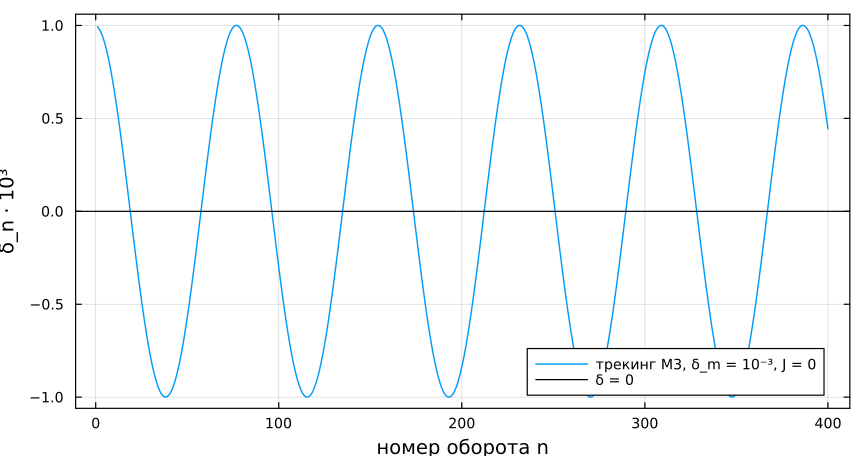

min = -1.0001e-03  max = 1.0008e-03  half-range = 1.0004e-03
M1 = 9.5245e-07   |M1| / half-range = 9.52e-04
простое среднее за 800 оборотов = 1.1954e-05  (ещё качается)


In [3]:
z0 = init(DM, 0.0, 0.0)
@time Z3 = track(step_M3, z0, N_LIVE)
d = deltas(Z3)
p = phis_note(Z3)
deq_M1 = M1(DM, 0.0, 0.0)

plt = plot(1:N_SHOW, d[1:N_SHOW] .* 1e3,
           lw = 1.2, xlabel = "номер оборота n", ylabel = "δ_n · 10³",
           label = "трекинг M3, δ_m = 10⁻³, J = 0")
hline!(plt, [0], color = :black, lw = 1, label = "δ = 0")
display(plt)

@printf("min = %.4e  max = %.4e  half-range = %.4e\n",
        minimum(d), maximum(d), (maximum(d) - minimum(d)) / 2)
@printf("M1 = %.4e   |M1| / half-range = %.2e\n", deq_M1, abs(deq_M1) / ((maximum(d) - minimum(d)) / 2))
@printf("простое среднее за %d оборотов = %.4e  (ещё качается)\n", N_LIVE, mean(d))


## Как достают центр

$\delta_{\mathrm{eq}}$ — среднее по бесконечному времени. На конечном ряде простое среднее $\frac1N\sum\delta_n$ осциллирует с периодом $T_s$. Огибающая ошибки

$$
\frac{\delta_m}{N\sin(\pi Q_s)}.
$$

При $\delta_m=10^{-3}$ за $1.2\cdot10^4$ оборотов она ещё $6.3\cdot10^{-7}$, одного порядка с самим $\delta_{\mathrm{eq}}$. Для одного процента простым средним нужно $\sim2.6\cdot10^6$ оборотов. Гармонический фит

$$
\delta_n
=
\delta_{\mathrm{eq}}
+a_1\cos(2\pi Q n)+b_1\sin(2\pi Q n)
+a_2\cos(4\pi Q n)+b_2\sin(4\pi Q n)
$$

с подгонкой частоты даёт один процент за $\approx408$ оборотов. В таблицах заметки стоит он. Частоту нужно брать измеренную: линейный $Q_s$ за $155$ периодов уезжает на $0.4$ периода из-за $\Delta Q_s/Q_s\approx-0.3\%$.

Ниже тот же короткий ряд: скользящее среднее ещё качается, фит уже называет центр. Цифры сходимости на $10^4$ оборотов — из заметки, этот ряд их не повторяет.


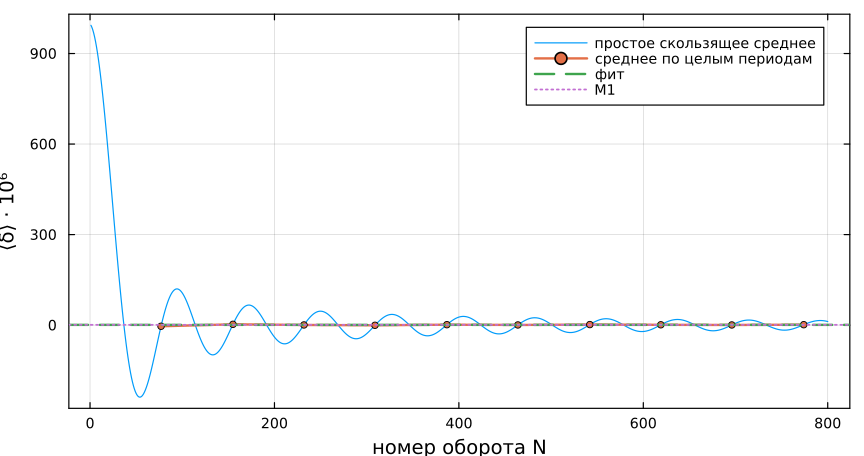

Qs meas = 0.012925   T_s = 77.4 turns   periods in row = 10
фит δ_eq = 9.0125e-07   δ_m = 9.99765e-04   φ̂ = 0.2064
M1(δ_m фита) = 9.5200e-07


простое среднее = 1.1954e-05   среднее по 10 периодам = 1.4095e-06
огибающая на N = 800: 3.079e-05

из заметки, N = 12000, δ_m = 10⁻³, J = 0:
  M1 = 0.9520e-6   M2 = 0.9546e-6   M3 фит = 0.9499e-6
  ошибка простого среднего = 6.3e-7
  1 % простым средним ≈ 2.6e6 оборотов; фитом ≈ 408 оборотов


In [4]:
m = measure_synchrotron(d, p; Qs = abs(Qs_smooth))
rm = runmean(d)
Ts = 1 / m.Qs_meas
K = max(1, floor(Int, N_LIVE / Ts))
Nk = [round(Int, k * Ts) for k in 1:K]
pm = [mean(d[1:n]) for n in Nk]
env = DM ./ ((1:N_LIVE) .* sin(pi * m.Qs_meas))

plt = plot(xlabel = "номер оборота N", ylabel = "⟨δ⟩ · 10⁶", legend = :topright)
plot!(plt, 1:N_LIVE, rm .* 1e6, lw = 1, label = "простое скользящее среднее")
plot!(plt, Nk, pm .* 1e6, lw = 2, marker = :circle, ms = 3, label = "среднее по целым периодам")
hline!(plt, [m.delta_eq * 1e6], lw = 2, ls = :dash, label = "фит")
hline!(plt, [deq_M1 * 1e6], lw = 1.5, ls = :dot, label = "M1")
display(plt)

@printf("Qs meas = %.6f   T_s = %.1f turns   periods in row = %d\n", m.Qs_meas, Ts, K)
@printf("фит δ_eq = %.4e   δ_m = %.5e   φ̂ = %.4f\n", m.delta_eq, m.delta_m_fit, m.phi_hat)
@printf("M1(δ_m фита) = %.4e\n", M1(m.delta_m_fit, 0.0, 0.0))
@printf("простое среднее = %.4e   среднее по %d периодам = %.4e\n", mean(d), K, pm[end])
@printf("огибающая на N = %d: %.3e\n", N_LIVE, env[N_LIVE])
println()
println("из заметки, N = 12000, δ_m = 10⁻³, J = 0:")
println("  M1 = 0.9520e-6   M2 = 0.9546e-6   M3 фит = 0.9499e-6")
println("  ошибка простого среднего = 6.3e-7")
println("  1 % простым средним ≈ 2.6e6 оборотов; фитом ≈ 408 оборотов")


## Бетатрон без синхротрона

ВЧ выключен, $\delta=0$, амплитуда $20$ мм. Удлинение пути за один оборот скачет с бетатронной фазой. Скользящее среднее за десятки оборотов садится на

$$
\Lambda = -\frac{2\pi}{C} J\,\xi.
$$

По $x$ внутри оборота есть большой знакопеременный кусок $\int x_\beta/\rho\,\mathrm{d}s$; за оборот он сокращается, остаётся квадратичный вековой член. По $y$ линейного куска нет, и $\Delta L(s)$ сразу идёт вдоль прямой $\Lambda_y s$.

Вертикаль круче: $|\xi_y|$ больше и при той же амплитуде действие больше, потому что $\beta_y=4.05$ м против $\beta_x=19.4$ м в точке наблюдения. На $400$ оборотах заметка дала $\Lambda_x=0.808\cdot10^{-6}$ и $\Lambda_y=5.88\cdot10^{-6}$. Здесь $200$ оборотов — достаточно, чтобы среднее село на ту же прямую.


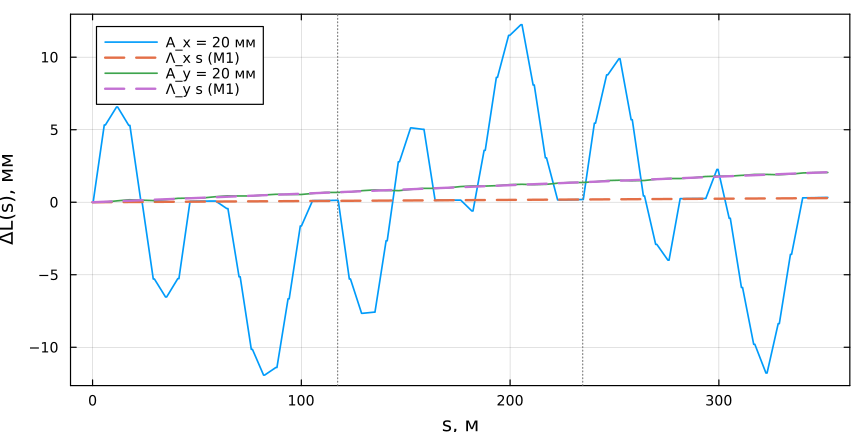

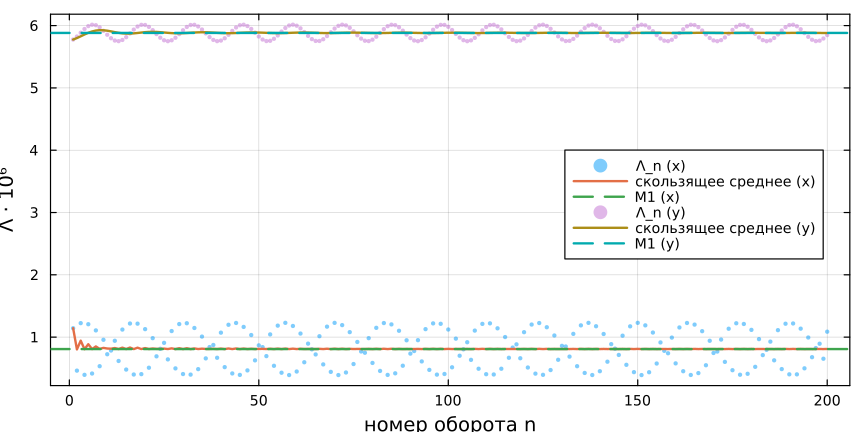

J_x = 1.0326e-05 m   Λ_x M1 = 8.0832e-07   <Λ_n> = 8.0976e-07
J_y = 4.9354e-05 m   Λ_y M1 = 5.8822e-06   <Λ_n> = 5.8814e-06


In [5]:
function within_turn(Ax, Ay, nturns)
    z = user_to_canonical([Ax, 0.0, Ay, 0.0, 0.0, 0.0], ref, C, HARM)
    s = [0.0]; L = [0.0]; st = 0.0
    for _ in 1:nturns, e in lat.elements
        z = exact_track_element(z, e, ref, C)
        st += (hasproperty(e, :L) ? e.L : 0.0)
        push!(s, st)
        push!(L, -z[5])
    end
    return s, L
end

function per_turn_L(Ax, Ay, N)
    z = user_to_canonical([Ax, 0.0, Ay, 0.0, 0.0, 0.0], ref, C, HARM)
    out = zeros(N)
    for n in 1:N
        l0 = z[5]
        z = exact_track_turn(z, lat, ref, C)
        out[n] = -(z[5] - l0) / C
    end
    return out
end

JxF = csJ(A_FAST, po.x)
JyF = csJ(A_FAST, po.y)
LamX = formula_B_Lambda(C, JxF, xi.x[2], 0.0, 0.0)
LamY = formula_B_Lambda(C, 0.0, 0.0, JyF, xi.y[2])

sX, LX = within_turn(A_FAST, 0.0, 3)
sY, LY = within_turn(0.0, A_FAST, 3)
p1 = plot(xlabel = "s, м", ylabel = "ΔL(s), мм", legend = :topleft, size = (720, 360))
plot!(p1, sX, LX .* 1e3, lw = 1.4, label = "A_x = 20 мм")
plot!(p1, [0, 3C], [0, 3C * LamX] .* 1e3, ls = :dash, lw = 2, label = "Λ_x s (M1)")
plot!(p1, sY, LY .* 1e3, lw = 1.4, label = "A_y = 20 мм")
plot!(p1, [0, 3C], [0, 3C * LamY] .* 1e3, ls = :dash, lw = 2, label = "Λ_y s (M1)")
vline!(p1, [C, 2C], color = :gray, ls = :dot, label = "")
display(p1)

LnX = per_turn_L(A_FAST, 0.0, N_BETA)
LnY = per_turn_L(0.0, A_FAST, N_BETA)
p2 = plot(xlabel = "номер оборота n", ylabel = "Λ · 10⁶", legend = :right, size = (720, 360))
scatter!(p2, 1:N_BETA, LnX .* 1e6, ms = 2, msw = 0, alpha = 0.5, label = "Λ_n (x)")
plot!(p2, 1:N_BETA, runmean(LnX) .* 1e6, lw = 2, label = "скользящее среднее (x)")
hline!(p2, [LamX * 1e6], ls = :dash, lw = 2, label = "M1 (x)")
scatter!(p2, 1:N_BETA, LnY .* 1e6, ms = 2, msw = 0, alpha = 0.5, label = "Λ_n (y)")
plot!(p2, 1:N_BETA, runmean(LnY) .* 1e6, lw = 2, label = "скользящее среднее (y)")
hline!(p2, [LamY * 1e6], ls = :dash, lw = 2, label = "M1 (y)")
display(p2)

@printf("J_x = %.4e m   Λ_x M1 = %.4e   <Λ_n> = %.4e\n", JxF, LamX, mean(LnX))
@printf("J_y = %.4e m   Λ_y M1 = %.4e   <Λ_n> = %.4e\n", JyF, LamY, mean(LnY))


## Оба вклада вместе

Тот же $\delta_m=10^{-3}$ и горизонтальная амплитуда $10$ мм. Бетатрон сдвигает уровень среднего на $-\Lambda/\eta_0$ и не меняет скорость синхротронной сходимости: $\delta$ меняется только в ВЧ-ударе, а $\Lambda$ входит как постоянный сдвиг центра.

Из заметки, $N=12000$: без бетатрона $\delta_{\mathrm{eq}}\approx0.95\cdot10^{-6}$; при $A_x=10$ мм — $1.33\cdot10^{-6}$; при $A_y=20$ мм — $11.94\cdot10^{-6}$.


  1.486424 seconds (136.66 M allocations: 6.947 GiB, 24.28% gc time)


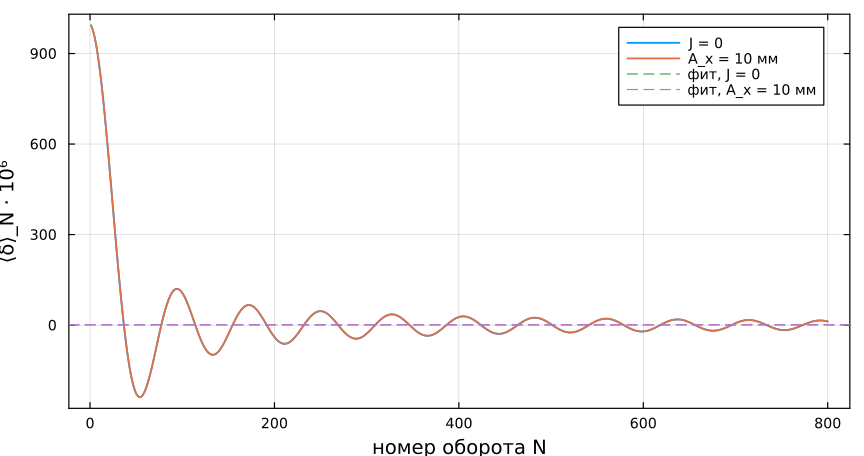

Λ (M1) = 2.0208e-07   −Λ/η0 = 3.7860e-07
фит J=0:     9.0125e-07     M1 = 9.5200e-07
фит A_x=10:  1.2798e-06     M1 = 1.3299e-06
заметка, N = 12000:  0.9499e-6  и  1.3289e-6


In [6]:
zB = init(DM, AX_BOTH, 0.0)
@time ZB = track(step_M3, zB, N_LIVE)
dB = deltas(ZB)
pBphi = phis_note(ZB)
mB = measure_synchrotron(dB, pBphi; Qs = abs(Qs_smooth))
JxB = csJ(AX_BOTH, po.x)
LamB = formula_B_Lambda(C, JxB, xi.x[2], 0.0, 0.0)
deq_shift = -LamB / pe.eta0

plt = plot(xlabel = "номер оборота N", ylabel = "⟨δ⟩_N · 10⁶", legend = :topright)
plot!(plt, 1:N_LIVE, runmean(d) .* 1e6, lw = 1.5, label = "J = 0")
plot!(plt, 1:N_LIVE, runmean(dB) .* 1e6, lw = 1.5, label = "A_x = 10 мм")
hline!(plt, [m.delta_eq * 1e6], ls = :dash, label = "фит, J = 0")
hline!(plt, [mB.delta_eq * 1e6], ls = :dash, label = "фит, A_x = 10 мм")
display(plt)

@printf("Λ (M1) = %.4e   −Λ/η0 = %.4e\n", LamB, deq_shift)
@printf("фит J=0:     %.4e     M1 = %.4e\n", m.delta_eq, M1(m.delta_m_fit, 0.0, 0.0))
@printf("фит A_x=10:  %.4e     M1 = %.4e\n", mB.delta_eq, M1(mB.delta_m_fit, JxB, 0.0))
println("заметка, N = 12000:  0.9499e-6  и  1.3289e-6")


## Тор

Замкнутая кривая из раздела про одну частицу — уже тор размерности один: окружность фиксированного действия $J_s$ в плоскости фазы и $\delta$. Её центр и есть $\delta_{\mathrm{eq}}$.

После нормальной формы однооборотной карты остаются три действия и три угла. Каждая пара нормальных координат лежит на своей окружности

$$
q_k=\sqrt{2J_k}\,\cos\theta_k,
\qquad
p_k=-\sqrt{2J_k}\,\sin\theta_k,
\qquad
J_k=\tfrac12(q_k^2+p_k^2).
$$

Произведение трёх окружностей — трёхмерный тор в шестимерном фазовом пространстве. Один оборот наматывает углы:

$$
\theta_k(n)=\theta_k(0)+2\pi Q_k\,n.
$$

Если $1,Q_x,Q_y,Q_s$ линейно независимы над рациональными числами, намотка заполняет тор, и среднее по оборотам совпадает со средним по углам. Косинусы и синусы интегрируются в нуль, остаётся

$$
\delta_{\mathrm{eq}}=\delta^\ast+d_x J_x+d_y J_y+d_s J_s.
$$

Сдвиг начальных фаз при тех же $J$ его не меняет. Модель M2 считает этот интеграл по сетке углов и по орбите не ходит. M3 идёт по одной намотке.

Следующая ячейка строит нормальную форму произведения Ли — это самая тяжёлая ячейка тетради, десятки секунд. На этом кольце $Q_x/Q_s\approx35.7$.


In [7]:
F = one_turn_factor_rf(lat, cav, ref, C)
@time nf = dragt_finn_nf6d(F)
Mmap = factor_to_map(F)
Qlin = nf.mu ./ (2pi)
Qs = abs(Qlin[3])
J0 = nf6d_actions(nf, z0)
deq_M2 = nf6d_delta_eq(nf, J0)
d_note = [2pi / C * xi.x[2] / pe.eta0,
          2pi / C * xi.y[2] / pe.eta0,
          -pe.eta1 * nf.sigma_delta_s^2 / pe.eta0]

@printf("Q = (%.6f, %.6f, %.6f)\n", Qlin...)
@printf("Qx / Qs = %.2f\n", abs(Qlin[1] / Qlin[3]))
@printf("z* = %s\n", string(nf.zstar))
@printf("d (NF)  = %.6e  %.6e  %.6e\n", nf.d...)
@printf("d (M1)  = %.6e  %.6e  %.6e\n", d_note...)
@printf("J (NF)  = %.4e  %.4e  %.4e m\n", J0...)
@printf("M2 = %.4e    M3 фит (короткий ряд) = %.4e    M1 = %.4e\n", deq_M2, m.delta_eq, deq_M1)
@printf("δ_m (NF) = σ_δ √(2 J_s) = %.5e\n", sqrt(2 * J0[3]) * nf.sigma_delta_s)


  2.116381 seconds (8.10 M allocations: 432.986 MiB, 1.83% gc time, 97.40% compilation time)


Q = (0.462452, 0.462016, 0.012960)
Qx / Qs = 35.68
z* = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
d (NF)  = 1.466524e-01  2.232894e-01  2.477064e-03
d (M1)  = 1.466526e-01  2.232897e-01  2.477064e-03
J (NF)  = 4.6162e-12  5.9079e-38  3.8536e-04 m
M2 = 9.5457e-07    M3 фит (короткий ряд) = 9.0125e-07    M1 = 9.5245e-07
δ_m (NF) = σ_δ √(2 J_s) = 1.00111e-03


## Четыре модели на одной точке

Одна и та же структура, один тонкий ВЧ.

- **M1** — формула из времени пролёта. От напряжения $\delta_{\mathrm{eq}}$ не зависит.
- **M2** — среднее лабораторного $\delta$ по тору нормальной формы.
- **M3** — поэлементный симплектический трекинг, эталон. Выше — короткий ряд; в заметке — $12000$ оборотов.
- **M4** — полином степени $3$ того же произведения Ли, без симплектичности. За короткое время среднее почти не портит; при $\delta_m=10^{-3}$ разница фитов с M3 в заметке $0.2\%$.

Коэффициенты $\partial\delta_{\mathrm{eq}}/\partial J$ у M1 и M2 совпали на уровне $10^{-6}$. При $\delta_m\le10^{-3}$ трекинг лежит в пределах $0.25\%$ от формулы. При $\delta_m\to0$ сдвиг стремится к нулю: постоянной добавки при тонком ВЧ нет.

Рисунки линейности по $\delta_m^2$ и по $J$ — из полного прогона, здесь они не пересчитываются.


  0.088818 seconds (1.52 M allocations: 28.682 MiB, 20.12% gc time, 40.79% compilation time)
                   M1           M2       M3 фит       M4 фит


живой      9.5200e-07   9.5457e-07   9.0125e-07   9.0312e-07

заметка, δ_m = 10⁻³, J = 0, N = 12000:
полный     9.5200e-07   9.5460e-07   9.4990e-07   9.5190e-07


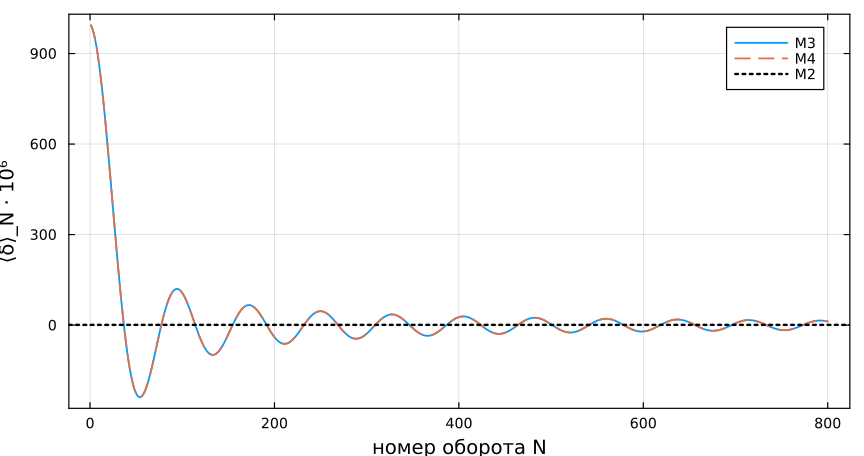

In [8]:
step_M4(z) = evaluate_map(Mmap, z)
@time Z4 = track(step_M4, z0, N_LIVE)
m4 = measure_synchrotron(deltas(Z4), phis_note(Z4); Qs = Qs)

@printf("%-8s %12s %12s %12s %12s\n", "", "M1", "M2", "M3 фит", "M4 фит")
@printf("%-8s %12.4e %12.4e %12.4e %12.4e\n",
        "живой", M1(m.delta_m_fit, 0.0, 0.0), deq_M2, m.delta_eq, m4.delta_eq)
println()
println("заметка, δ_m = 10⁻³, J = 0, N = 12000:")
@printf("%-8s %12.4e %12.4e %12.4e %12.4e\n",
        "полный", 0.9520e-6, 0.9546e-6, 0.9499e-6, 0.9519e-6)

plt = plot(xlabel = "номер оборота N", ylabel = "⟨δ⟩_N · 10⁶", legend = :topright)
plot!(plt, 1:N_LIVE, runmean(d) .* 1e6, lw = 1.5, label = "M3")
plot!(plt, 1:N_LIVE, runmean(deltas(Z4)) .* 1e6, lw = 1.5, ls = :dash, label = "M4")
hline!(plt, [deq_M2 * 1e6], color = :black, ls = :dot, lw = 2, label = "M2")
display(plt)


Тест A заметки: $\delta_{\mathrm{eq}}$ линеен по $\delta_m^2$ и проходит через нуль.

![Тест A](../note/figs/fig_A_delta_eq.png)

Тест B: $\Lambda$ линейна по действию, наклон $-2\pi\xi/C$.

![Тест B](../note/figs/fig_B_lambda.png)

Сходимость среднего и сравнение M3 с M4 на полном ряде:

![Сходимость](../note/figs/fig_T_convergence.png)

![M3 против M4](../note/figs/fig_M3_M4.png)


## Что тетрадь не закрывает

Секступолей в `magnetic_2.opt` нет, спиновая динамика в код не входит.

Секступоль входит в $\Lambda$ через хроматичность. Условие $\xi_x=\xi_y=0$ убирает бетатронное удлинение первого порядка по $J$. Остаётся

$$
\delta_{\mathrm{eq}}=-\frac{\eta_1\langle\delta^2\rangle}{\eta_0}.
$$

Тем же секступолем двигается $\eta_1$, через дисперсию второго порядка:

$$
\Delta\eta_1=-\frac{1}{2C}\oint K_2 D_1^3\,\mathrm{d}s.
$$

Это другой вес, не $\beta D$, которым правится $\xi$. Обнуление $\xi$ и обнуление $\eta_1$ — разные условия. $\eta_0$ секступоль не двигает.

Кинематическая часть $\eta_1$,

$$
-\frac{\alpha_0}{\gamma_s^2}+\frac{3\gamma_s^2-1}{2\gamma_s^4}\approx0.678,
$$

от магнитов не зависит. Измеренное $\eta_1=1.017$, геометрическое $\alpha_1\approx0.339$. Чтобы погасить весь $\eta_1$, интеграл по $K_2 D_1^3$ должен перекрыть и геометрию, и эту кинематику.

Даже при $\delta_{\mathrm{eq}}=0$ средний лоренц-фактор остаётся амплитудно-зависимым:

$$
\gamma_{\mathrm{eff}}
=
\gamma_s
+\beta_s^2\gamma_s\,\delta_{\mathrm{eq}}
+\frac{\beta_s^2\delta_m^2}{4\gamma_s}.
$$

Второе слагаемое при $\Lambda=0$ на этой решётке составляет около $20\%$ вклада от $\delta_{\mathrm{eq}}$:

$$
\frac{|\eta_0|}{2|\eta_1|\gamma_s^2}\approx0.20.
$$

Спиновый тюн магнитного кольца идёт с $\gamma$, поэтому разброс по амплитудам остаётся. Спин в этом проекте ещё не считался.

Оптика по-прежнему зашита в скрипт прогона. Вынести решётку в отдельный объект, поставить два семейства секступолей и прогнать M3 при $\xi=0$ и при $\eta_1=0$ — следующий шаг, после того как эта тетрадь читается.


In [9]:
alpha0 = pe.eta0 + 1 / ref.gamma^2
eta1_kin = -alpha0 / ref.gamma^2 + (3 * ref.gamma^2 - 1) / (2 * ref.gamma^4)
eta1_geom = pe.eta1 - eta1_kin
ratio = abs(pe.eta0) / (2 * abs(pe.eta1) * ref.gamma^2)
dgamma_eq = ref.beta^2 * ref.gamma * (-pe.eta1 * DM^2 / (2 * pe.eta0))
dgamma_kin = ref.beta^2 * DM^2 / (4 * ref.gamma)
@printf("alpha0 = %.6f\n", alpha0)
@printf("eta1 = %.6f = geom %.6f + kin %.6f\n", pe.eta1, eta1_geom, eta1_kin)
@printf("|η0| / (2 |η1| γs²) = %.3f\n", ratio)
@printf("при Λ = 0 и dm = %.1e:\n", DM)
@printf("  β² γ δ_eq     = %.4e\n", dgamma_eq)
@printf("  β² dm² / (4γ) = %.4e\n", dgamma_kin)
@printf("  отношение kin / |δeq-член| = %.3f\n", abs(dgamma_kin / dgamma_eq))


alpha0 = 0.230399


eta1 = 1.016756 = geom 0.338548 + kin 0.678208
|η0| / (2 |η1| γs²) = 0.201
при Λ = 0 и dm = 1.0e-03:
  β² γ δ_eq     = 2.5696e-07
  β² dm² / (4γ) = 5.1541e-08
  отношение kin / |δeq-член| = 0.201
